# Sistema bayesiano de recomendación de películas

El objetivo es estimar las calificaciones que un usuario podría asignar a películas que no ha valorado. Se utiliza una factorización matricial con efectos de usuario y película y cinco factores latentes.

El análisis compara una verosimilitud normal con una normal truncada entre 1 y 5. El 80 % de las calificaciones se destina al ajuste, el 10 % a seleccionar la verosimilitud y el resto a evaluar la predicción frente a la media de entrenamiento.

La base procesada reúne MovieLens y la encuesta del proyecto. Esta integración difiere del análisis separado planteado en el Avance 2 y requiere una justificación en el informe. La partición reserva calificaciones individuales; no representa un experimento con usuarios completamente nuevos. Las dos verosimilitudes son aproximaciones continuas a una escala discreta de cinco valores.


## Preparación del entorno

La primera celda carga las tres tablas de datos procesados desde un archivo ZIP. Las funciones de partición, predicción y diagnóstico están definidas en este notebook. Para ejecutar los dos ajustes en Colab se recomienda una sesión con GPU y seguir el orden de las celdas.


In [1]:
from google.colab import files
from pathlib import Path
from io import BytesIO
import zipfile
import os

print("Selecciona proyecto_limpio.zip o el ZIP original del proyecto")
subidos = files.upload()
assert len(subidos) == 1, "Selecciona un único ZIP."
nombre, contenido = next(iter(subidos.items()))
raiz = Path('/content/Bayesian_recommendation_system')
# Se lee el archivo recién cargado, aunque Colab haya modificado su nombre.
necesarios = ['data/processed/users_clean.csv',
              'data/processed/items_clean.csv',
              'data/processed/ratings_clean.csv']
with zipfile.ZipFile(BytesIO(contenido)) as z:
    recuperados = {}
    for relativo in necesarios:
        coincidencias = [info for info in z.infolist()
            if info.filename.replace('\\','/').endswith(relativo)]
        assert len(coincidencias) == 1, f'No hay una copia única de {relativo}'
        recuperados[relativo] = z.read(coincidencias[0])
    for relativo, datos in recuperados.items():
        salida = raiz / relativo
        salida.parent.mkdir(parents=True, exist_ok=True)
        salida.write_bytes(datos)
os.chdir(raiz)
print('OK: tres tablas recuperadas en', raiz)
print('Las funciones del modelo están integradas en este notebook.')


Selecciona proyecto_limpio.zip o el ZIP original del proyecto


Saving proyecto_limpio.zip to proyecto_limpio.zip
OK: tres tablas recuperadas en /content/Bayesian_recommendation_system
Las funciones del modelo están integradas en este notebook.


In [2]:
%pip install -q "pymc==5.25.1" "arviz==0.21.0" "numpy<2.3" "matplotlib<3.11" numpyro scipy h5netcdf


In [3]:
from pathlib import Path
import sys, json, hashlib, platform, importlib.metadata, time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import jax
import matplotlib.pyplot as plt

# Asegurar precisión nativa rápida (float32) en GPU
jax.config.update("jax_enable_x64", False)

candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'Bayesian_recommendation_system']
ROOT = next((p for p in candidatos if (p / 'data/processed/ratings_clean.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Sube primero el ZIP con data/processed/.')

SEED, K = 42, 4
DRAWS, TUNE, CHAINS = 600, 600, 4
TARGET_ACCEPT = 0.90
OUT = ROOT / 'resultados_rapidos_150'
OUT.mkdir(exist_ok=True)
print('Backend:', jax.default_backend(), '| float64:', jax.config.jax_enable_x64)

ruta = ROOT / 'data/processed'
users = pd.read_csv(ruta / 'users_clean.csv')
items = pd.read_csv(ruta / 'items_clean.csv')
ratings = pd.read_csv(ruta / 'ratings_clean.csv')
ratings = ratings[ratings.user_id.isin(users.user_id) & ratings.movie_id.isin(items.movie_id)].copy()

# 1. Mantener los 55 encuestados activos + 95 usuarios puente de MovieLens (150 usuarios)
todos_encuesta = users.loc[users['source'] == 'encuesta', 'user_id'].unique()
ids_encuesta = np.intersect1d(todos_encuesta, ratings['user_id'].unique())
pelis_encuesta = ratings.loc[ratings['user_id'].isin(ids_encuesta), 'movie_id'].unique()

ratings_ml = ratings[~ratings['user_id'].isin(todos_encuesta)]
ranking_puente = (
    ratings_ml.assign(es_puente=ratings_ml['movie_id'].isin(pelis_encuesta))
    .groupby('user_id')
    .agg(votos_puente=('es_puente', 'sum'), votos_totales=('rating', 'count'))
    .sort_values(['votos_puente', 'votos_totales'], ascending=False)
)

n_ml = 150 - len(ids_encuesta)  # 95 usuarios puente de MovieLens
usuarios_150 = np.concatenate([ids_encuesta, ranking_puente.head(n_ml).index.to_numpy()])
ratings = ratings[ratings['user_id'].isin(usuarios_150)].copy()

# 2. Filtrar películas con >= 15 votos (protegiendo siempre las 20 de la encuesta)
conteo_pelis = ratings['movie_id'].value_counts()
pelis_activas = conteo_pelis[conteo_pelis >= 15].index.union(pelis_encuesta)
ratings = ratings[ratings['movie_id'].isin(pelis_activas)].copy()

# 3. Reindexar y particionar 80 / 10 / 10
ratings['user_idx'], user_ids = pd.factorize(ratings.user_id)
ratings['movie_idx'], movie_ids = pd.factorize(ratings.movie_id)

def particionar(df_in, seed=42):
    df = df_in.reset_index(drop=True).copy()
    df['row_id'] = np.arange(len(df))
    order = np.random.default_rng(seed).permutation(len(df))
    n_train, n_val = int(0.8 * len(df)), int(0.1 * len(df))
    return tuple(df.iloc[ix].reset_index(drop=True) for ix in
                 (order[:n_train], order[n_train:n_train+n_val], order[n_train+n_val:]))

train, validation, test = particionar(ratings, SEED)
print(f"Usuarios: {len(user_ids)} (Encuesta: {len(ids_encuesta)} | MovieLens: {n_ml}) | Películas: {len(movie_ids)}")
print(f"Interacciones -> Train: {len(train)} | Validation: {len(validation)} | Test: {len(test)}")

Backend: gpu | float64: False
Usuarios: 150 (Encuesta: 55 | MovieLens: 95) | Películas: 641
Interacciones -> Train: 19847 | Validation: 2480 | Test: 2482


## Datos de usuarios, películas y calificaciones

Se conservan las calificaciones cuyos identificadores aparecen en las tablas de usuarios y películas. Los índices consecutivos permiten acceder a los efectos y factores de cada entidad dentro del modelo.

La partición usa una permutación con semilla 42. Los tamaños de entrenamiento y validación se redondean hacia abajo y las filas restantes forman el conjunto de prueba. Se guardan los identificadores de las filas y la huella del archivo de calificaciones para reproducir la separación. Los conteos también identifican los casos reservados sin historial de usuario o película en entrenamiento.



=== Muestreando NORMAL ===


sample: 100%|██████████| 1200/1200 [01:12<00:00, 16.49it/s]
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/mlir.py:1406: UserWarning: Some donated buffers were not usable: float64[4,600,149], float64[4,600,640], float64[4,600,4,149], float64[4,600,4,640].
See an explanation at https://docs.jax.dev/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"
ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Tiempo (normal): 133.6 segundos
               grupo  cantidad  alertas  rhat_max  ess_bulk_min  ess_tail_min
   factores_latentes      3164     3113    1.9719           5.5          16.1
resto_y_predicciones       996        3    1.0180         263.8         606.1
{'divergencias': 0, 'bfmi_min': 0.574}

=== Muestreando STUDENT_T ===


sample: 100%|██████████| 1200/1200 [05:29<00:00,  3.64it/s]
/usr/local/lib/python3.13/dist-packages/jax/_src/interpreters/mlir.py:1406: UserWarning: Some donated buffers were not usable: float64[4,600,149], float64[4,600,640], float64[4,600,4,149], float64[4,600,4,640].
See an explanation at https://docs.jax.dev/en/latest/faq.html#buffer-donation.
  warnings.warn("Some donated buffers were not usable:"
ERROR:pymc.stats.convergence:The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Tiempo (student_t): 358.3 segundos
               grupo  cantidad  alertas  rhat_max  ess_bulk_min  ess_tail_min
   factores_latentes      3164     3129    1.8603           5.8          13.1
resto_y_predicciones       998        4    1.0192         274.1         504.2
{'divergencias': 0, 'bfmi_min': 0.524}


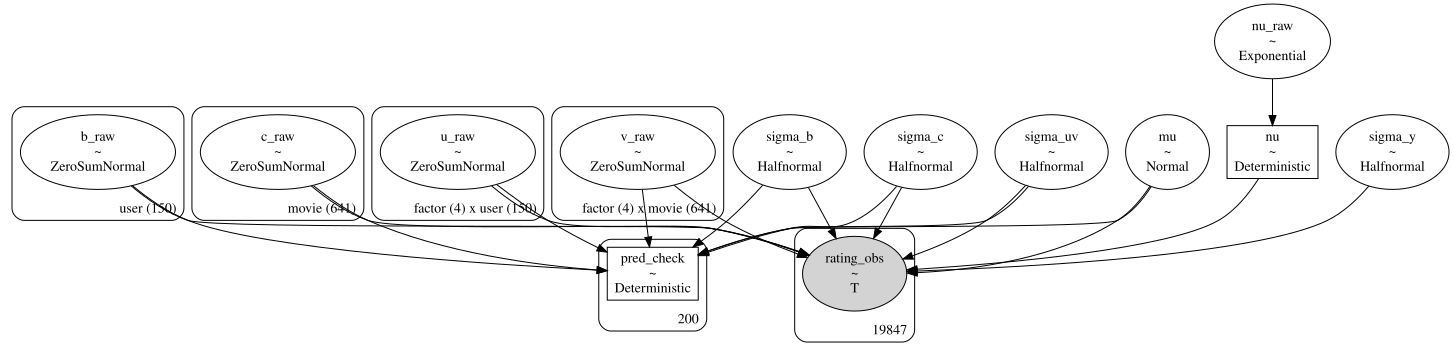

In [4]:
coords = {'user': user_ids, 'movie': movie_ids, 'factor': [f'f_{i}' for i in range(K)]}
chk = np.random.default_rng(SEED + 1).choice(len(train), min(200, len(train)), replace=False)

def construir_modelo(familia):
    ui, mi = train.user_idx.to_numpy(), train.movie_idx.to_numpy()
    with pm.Model(coords=coords) as modelo:
        mu  = pm.Normal('mu', mu=3.3, sigma=0.5)
        sb  = pm.HalfNormal('sigma_b', sigma=0.5)
        sc  = pm.HalfNormal('sigma_c', sigma=0.5)
        suv = pm.HalfNormal('sigma_uv', sigma=0.3)

        b = pm.ZeroSumNormal('b_raw', sigma=1, dims='user')
        c = pm.ZeroSumNormal('c_raw', sigma=1, dims='movie')
        u = pm.ZeroSumNormal('u_raw', sigma=1, dims=('factor', 'user'))
        v = pm.ZeroSumNormal('v_raw', sigma=1, dims=('factor', 'movie'))

        eta = mu + sb * b[ui] + sc * c[mi] + (suv ** 2) * (u[:, ui] * v[:, mi]).sum(axis=0)
        pm.Deterministic('pred_check', eta[chk])
        sy = pm.HalfNormal('sigma_y', sigma=0.8)

        if familia == 'normal':
            pm.Normal('rating_obs', mu=eta, sigma=sy, observed=train.rating.to_numpy())
        elif familia == 'student_t':
            nu = pm.Deterministic('nu', 2.0 + pm.Exponential('nu_raw', 0.1))
            pm.StudentT('rating_obs', nu=nu, mu=eta, sigma=sy, observed=train.rating.to_numpy())
        else:
            raise ValueError(familia)
    return modelo

def diagnosticar(trace):
    trace.posterior.load()
    trace.sample_stats.load()
    resumen = az.summary(trace, hdi_prob=0.94, round_to='none')
    umbral_ess = 100 * trace.posterior.sizes['chain']
    bad = (resumen.r_hat.gt(1.01) | resumen.ess_bulk.lt(umbral_ess) | resumen.ess_tail.lt(umbral_ess))
    divergencias = int(trace.sample_stats.diverging.sum())
    bfmi = np.asarray(az.bfmi(trace))
    latente = resumen.index.str.startswith(('u_raw[', 'v_raw['))
    filas = []
    for nombre, sel in [('factores_latentes', latente), ('resto_y_predicciones', ~latente)]:
        sub = resumen.loc[sel]
        filas.append({'grupo': nombre, 'cantidad': len(sub), 'alertas': int(bad[sel].sum()),
                      'rhat_max': round(sub.r_hat.max(), 4),
                      'ess_bulk_min': round(sub.ess_bulk.min(), 1),
                      'ess_tail_min': round(sub.ess_tail.min(), 1)})
    print(pd.DataFrame(filas).to_string(index=False))
    print({'divergencias': divergencias, 'bfmi_min': round(float(bfmi.min()), 3)})

modelos, traces = {}, {}
for familia in ('normal', 'student_t'):
    t0 = time.time()
    print(f"\n=== Muestreando {familia.upper()} ===")
    modelos[familia] = construir_modelo(familia)
    with modelos[familia]:
        traces[familia] = pm.sample(
            draws=DRAWS, tune=TUNE, chains=CHAINS,
            target_accept=TARGET_ACCEPT, random_seed=SEED,
            nuts_sampler='numpyro',
            nuts_sampler_kwargs={'chain_method': 'vectorized' if jax.default_backend() == 'gpu' else 'sequential'}
        )
    print(f"Tiempo ({familia}): {time.time() - t0:.1f} segundos")
    traces[familia].to_netcdf(OUT / f'trace_{familia}.nc')
    diagnosticar(traces[familia])

# Gráfico de óvalos (DAG) del modelo bayesiano
grafo_dag = pm.model_to_graphviz(modelos['student_t'])
grafo_dag.render(str(OUT / 'modelo_bayesiano_dag'), format='png', cleanup=True)
grafo_dag

,modelo,conjunto,n,RMSE,MAE
0,normal,validation,2480,0.8799,0.6896
1,normal,test_global,2482,0.8827,0.6989
2,normal,test_encuesta_UIS,81,1.0423,0.8627
3,student_t,validation,2480,0.8810,0.6880
4,student_t,test_global,2482,0.8815,0.6956
5,student_t,test_encuesta_UIS,81,1.0410,0.8567



Modelo ganador en validación: NORMAL (RMSE = 0.8799)


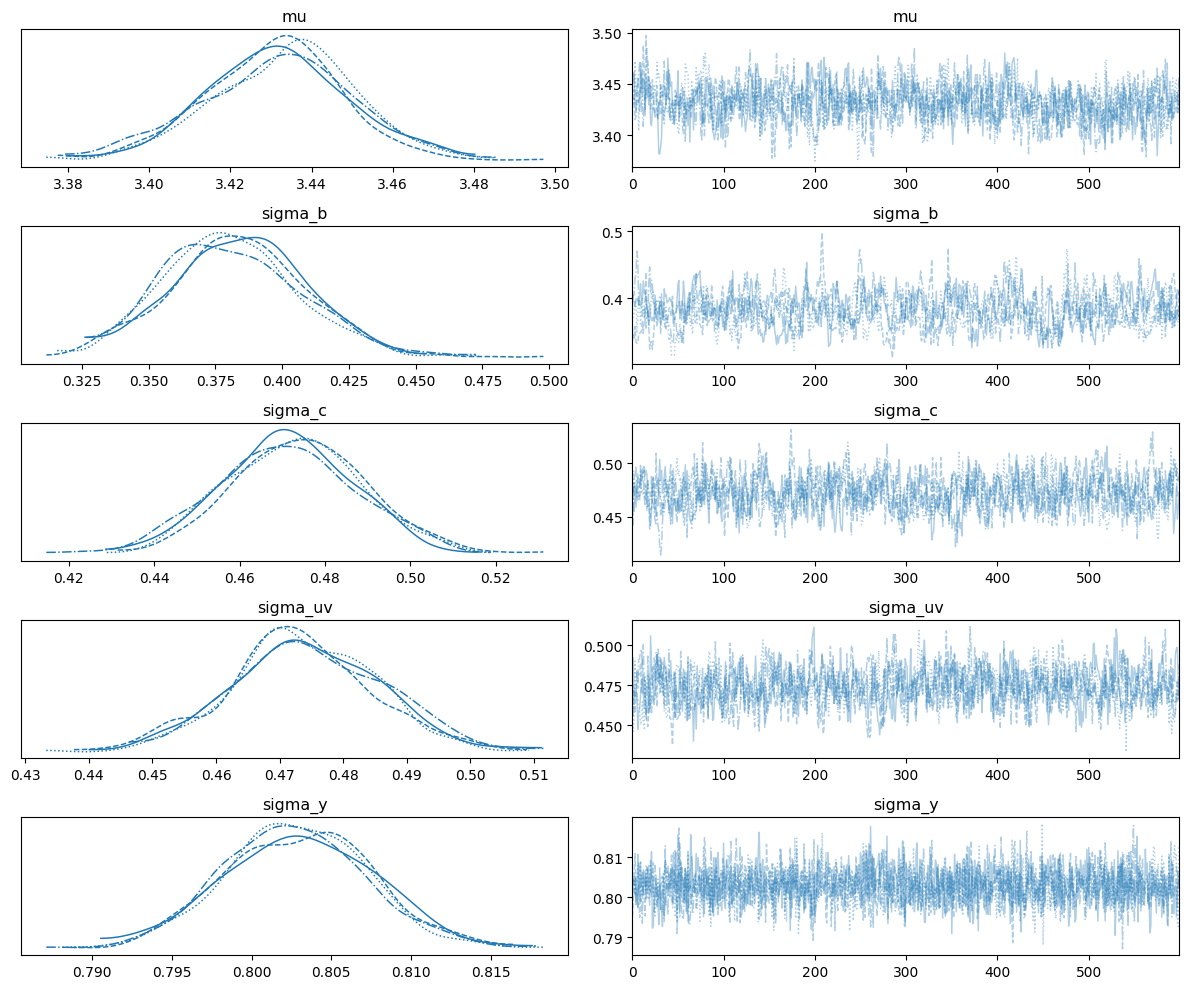

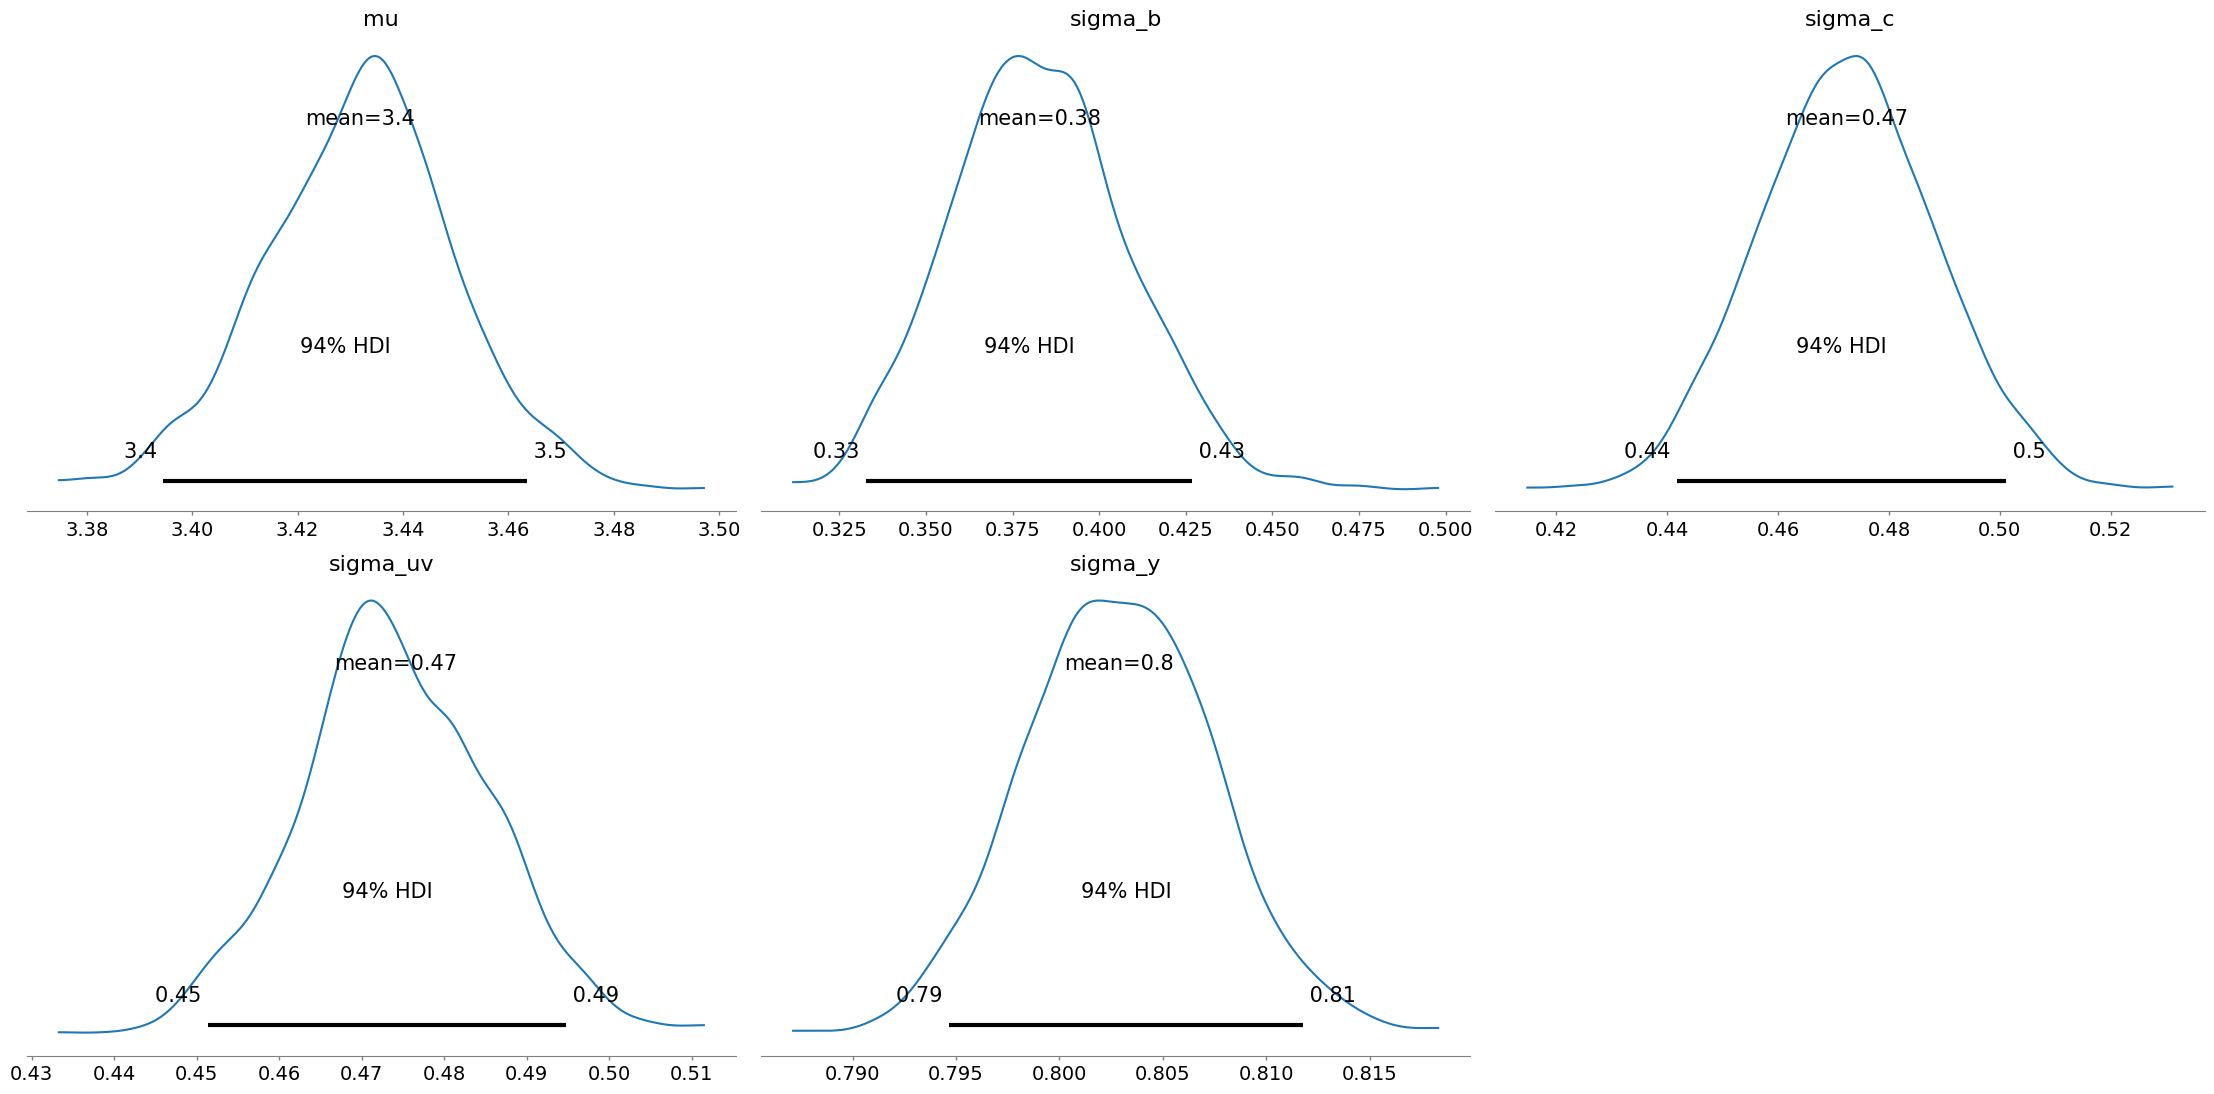


=== Calificaciones reales del encuestado ID 944 ===


,movie_title,rating
0,Toy Story (1995),5
3,Jurassic Park (1993),5
4,Groundhog Day (1993),5
8,Back to the Future (1985),5
10,Raiders of the Lost Ark (1981),5
2,"Lion King, The (1994)",4
9,Titanic (1997),4
5,Beauty and the Beast (1991),4
1,Men in Black (1997),3
7,Terminator 2: Judgment Day (1991),3


=== Top 10 películas no vistas recomendadas (NORMAL) ===


,movie_title,pred_estrellas,hdi_94_inf,hdi_94_sup
0,Schindler's List (1993),4.28,3.44,5.00
1,Good Will Hunting (1997),4.21,3.44,5.00
2,Wallace & Gromit: The Best of Aardman Animatio...,4.20,3.18,5.00
3,It's a Wonderful Life (1946),4.17,3.50,4.91
4,"Shawshank Redemption, The (1994)",4.17,3.44,4.86
5,"African Queen, The (1951)",4.15,3.30,5.00
6,"Silence of the Lambs, The (1991)",4.13,3.39,4.83
7,Amadeus (1984),4.12,3.32,4.93
8,L.A. Confidential (1997),4.10,3.12,5.00
9,Rear Window (1954),4.10,3.32,4.90


In [5]:
def muestras_prediccion(trace, pares, lote=256):
    post = trace.posterior.stack(sample=('chain', 'draw'))
    def arr(name, *dims):
        return post[name].transpose('sample', *dims).values
    mu, sb, sc, suv = (arr(n)[:, None] for n in ('mu', 'sigma_b', 'sigma_c', 'sigma_uv'))
    b, c = arr('b_raw', 'user'), arr('c_raw', 'movie')
    u, v = arr('u_raw', 'user', 'factor'), arr('v_raw', 'movie', 'factor')
    for start in range(0, len(pares), lote):
        block = pares.iloc[start:start+lote]
        ui, mi = block.user_idx.to_numpy(), block.movie_idx.to_numpy()
        eta = mu + sb * b[:, ui] + sc * c[:, mi] + (suv ** 2) * np.einsum('snk,snk->sn', u[:, ui, :], v[:, mi, :])
        yield start, np.clip(eta, 1.0, 5.0)

def predecir(trace, pares):
    pred = np.empty(len(pares))
    for start, draws_p in muestras_prediccion(trace, pares):
        pred[start:start+draws_p.shape[1]] = draws_p.mean(axis=0)
    return pred

# 1. Tabla comparativa de error (Validation, Test Global y Test Encuesta UIS)
filas_eval = []
for familia in ('normal', 'student_t'):
    for nombre, df_p in [('validation', validation), ('test_global', test), ('test_encuesta_UIS', test[test['source'] == 'encuesta'])]:
        err = predecir(traces[familia], df_p) - df_p['rating'].to_numpy()
        filas_eval.append({
            'modelo': familia, 'conjunto': nombre, 'n': len(df_p),
            'RMSE': round(float(np.sqrt(np.mean(err**2))), 4),
            'MAE': round(float(np.mean(np.abs(err))), 4)
        })
df_eval = pd.DataFrame(filas_eval)
display(df_eval)

# Seleccionar modelo ganador según RMSE en validation
val_rmse = df_eval[df_eval['conjunto'] == 'validation'].set_index('modelo')['RMSE']
ganador = val_rmse.idxmin()
print(f"\nModelo ganador en validación: {ganador.upper()} (RMSE = {val_rmse[ganador]:.4f})")

# 2. Gráficos de convergencia y posteriores con ArviZ
vars_graf = ['mu', 'sigma_b', 'sigma_c', 'sigma_uv', 'sigma_y'] + (['nu'] if ganador == 'student_t' else [])
az.plot_trace(traces[ganador], var_names=vars_graf)
plt.tight_layout()
plt.show()

az.plot_posterior(traces[ganador], var_names=vars_graf, hdi_prob=0.94)
plt.tight_layout()
plt.show()

# 3. Predecir calificaciones en películas NO vistas para un encuestado real de la UIS
def recomendar_encuestado(id_usuario, n=10):
    u_idx = np.where(user_ids == id_usuario)[0][0]
    col_tit = 'movie_title' if 'movie_title' in items.columns else 'title'

    print(f"\n=== Calificaciones reales del encuestado ID {id_usuario} ===")
    display(ratings[ratings['user_id'] == id_usuario].merge(items[['movie_id', col_tit]], on='movie_id')[[col_tit, 'rating']].sort_values('rating', ascending=False))

    vistas = ratings.loc[ratings['user_id'] == id_usuario, 'movie_idx'].unique()
    candidatos = np.setdiff1d(np.arange(len(movie_ids)), vistas)
    pares = pd.DataFrame({'user_idx': u_idx, 'movie_idx': candidatos})

    # Calcular media posterior e intervalo de credibilidad HDI 94%
    draws_list = [d for _, d in muestras_prediccion(traces[ganador], pares, lote=len(pares))]
    scores = draws_list[0]  # (n_samples, n_candidatos)

    res = pd.DataFrame({
        'movie_id': movie_ids[candidatos],
        'pred_estrellas': np.round(scores.mean(axis=0), 2),
        'hdi_94_inf': np.round(np.percentile(scores, 3, axis=0), 2),
        'hdi_94_sup': np.round(np.percentile(scores, 97, axis=0), 2),
    }).sort_values('pred_estrellas', ascending=False).head(n)

    print(f"=== Top {n} películas no vistas recomendadas ({ganador.upper()}) ===")
    display(res.merge(items[['movie_id', col_tit]], on='movie_id')[[col_tit, 'pred_estrellas', 'hdi_94_inf', 'hdi_94_sup']])

recomendar_encuestado(ids_encuesta[0], n=10)

Bloque 1: Evaluación predictiva (rating_obs) y contraste Normal vs. StudentTEste bloque genera muestras predictivas posteriores de rating_obs para comparar ambos modelos en validation, test_global y test_encuesta_UIS usando tres criterios: RMSE, MAE y Cobertura del HDI 94 % (qué porcentaje de las notas reales cae dentro del intervalo predicho). Además, inspecciona el parámetro $\nu$ de la t-Student para demostrar empíricamente si existen colas pesadas en los datos.

In [8]:
import numpy as np
import pandas as pd
import arviz as az
import matplotlib.pyplot as plt

# Recuperar trazas desde disco si la sesión se reinició
if 'traces' not in globals():
    traces = {
        'normal': az.from_netcdf(OUT / 'trace_normal.nc'),
        'student_t': az.from_netcdf(OUT / 'trace_student_t.nc')
    }

def generar_rating_obs(trace, pares, familia, seed=42):
    """Simula muestras de la distribución predictiva posterior rating_obs en [1, 5]."""
    rng = np.random.default_rng(seed)
    post = trace.posterior.stack(sample=('chain', 'draw'))

    mu  = post['mu'].values[:, None]
    sb  = post['sigma_b'].values[:, None]
    sc  = post['sigma_c'].values[:, None]
    suv = post['sigma_uv'].values[:, None]
    sy  = post['sigma_y'].values[:, None]

    b = post['b_raw'].transpose('sample', 'user').values
    c = post['c_raw'].transpose('sample', 'movie').values
    u = post['u_raw'].transpose('sample', 'user', 'factor').values
    v = post['v_raw'].transpose('sample', 'movie', 'factor').values

    ui = pares['user_idx'].to_numpy()
    mi = pares['movie_idx'].to_numpy()

    # Localización esperada eta_ij (forma: n_samples x n_pares)
    eta = mu + sb * b[:, ui] + sc * c[:, mi] + (suv ** 2) * np.einsum('snk,snk->sn', u[:, ui, :], v[:, mi, :])

    # Simular observación futura rating_obs según la familia
    if familia == 'normal':
        y_rep = rng.normal(loc=eta, scale=sy)
    elif familia == 'student_t':
        nu = post['nu'].values[:, None]
        y_rep = eta + sy * rng.standard_t(df=nu, size=eta.shape)
    else:
        raise ValueError(familia)

    y_rep = np.clip(y_rep, 1.0, 5.0)
    return np.clip(eta, 1.0, 5.0), y_rep

# 1. Revisar grados de libertad (nu) estimados por StudentT
nu_post = traces['student_t'].posterior['nu'].values.flatten()
print(f"Grados de libertad (nu) StudentT -> Media: {nu_post.mean():.2f} | HDI 94%: [{np.percentile(nu_post, 3):.2f}, {np.percentile(nu_post, 97):.2f}]")

# 2. Comparar métricas predictivas en Validation, Test Global y Test Encuesta UIS
filas = []
for familia in ('normal', 'student_t'):
    for nombre, df_p in [('validation', validation), ('test_global', test), ('test_encuesta_UIS', test[test['source'] == 'encuesta'])]:
        eta_draws, y_obs_draws = generar_rating_obs(traces[familia], df_p, familia)
        pred_media = y_obs_draws.mean(axis=0)
        hdi_inf = np.percentile(y_obs_draws, 3, axis=0)
        hdi_sup = np.percentile(y_obs_draws, 97, axis=0)

        y_real = df_p['rating'].to_numpy()
        cobertura = np.mean((y_real >= hdi_inf) & (y_real <= hdi_sup)) * 100

        filas.append({
            'modelo': familia,
            'conjunto': nombre,
            'n': len(df_p),
            'RMSE': round(float(np.sqrt(np.mean((pred_media - y_real) ** 2))), 4),
            'MAE': round(float(np.mean(np.abs(pred_media - y_real))), 4),
            'Cobertura_HDI94_%': round(float(cobertura), 1)
        })

df_metricas = pd.DataFrame(filas)
df_metricas.to_csv(OUT / 'comparacion_predictiva_final.csv', index=False)
display(df_metricas)

Grados de libertad (nu) StudentT -> Media: 13.95 | HDI 94%: [11.11, 17.75]


,modelo,conjunto,n,RMSE,MAE,Cobertura_HDI94_%
0,normal,validation,2480,0.8799,0.6931,93.9
1,normal,test_global,2482,0.8860,0.7070,93.7
2,normal,test_encuesta_UIS,81,1.0568,0.8934,95.1
3,student_t,validation,2480,0.8798,0.6914,94.5
4,student_t,test_global,2482,0.8835,0.7026,93.6
5,student_t,test_encuesta_UIS,81,1.0508,0.8830,95.1


Bloque 2: Matriz gráfica comparativa (Observadas vs. Predicciones en películas no vistas)Este bloque construye una visualización de completado de matriz con 18 encuestados de la UIS (filas) frente a las 20 películas de la encuesta (columnas), donde se aprecia exactamente qué películas calificó cada persona y cómo ambos modelos rellenan las celdas vacías (películas sin ver):Panel izquierdo: Matriz original dispersa (muestra las notas reales $1\text{–}5$ y deja en blanco las celdas sin calificar).Panel central: Matriz completada con el modelo Normal (las celdas sin ver aparecen rellenas con su predicción $\mathbb{E}[\tilde{y}_{ij}]$).Panel derecho: Matriz completada con el modelo StudentT (y abajo imprime las películas donde ambos modelos discrepan más).

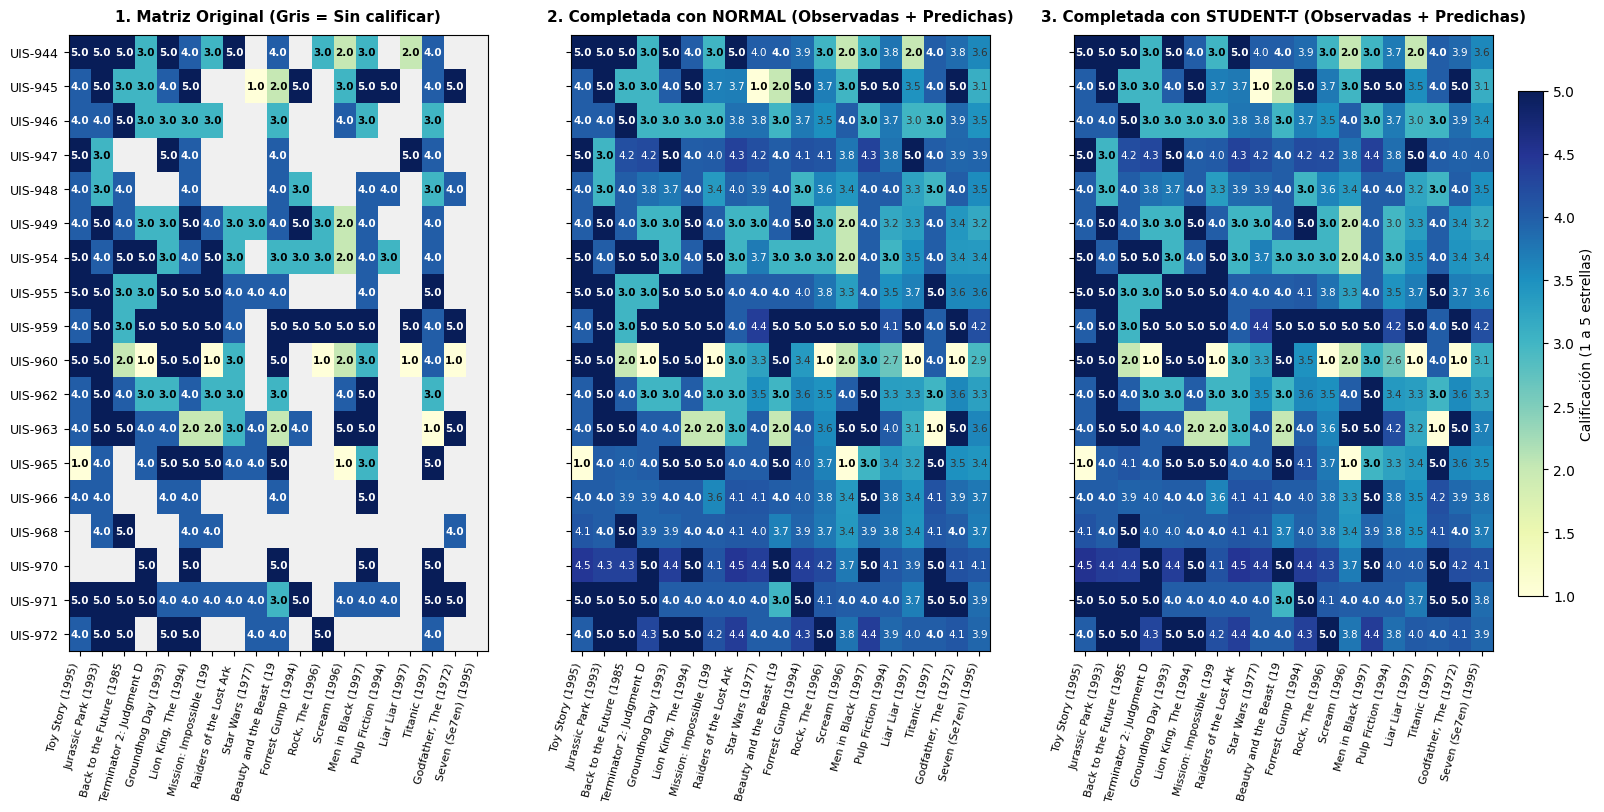


=== Mayores diferencias en películas NO vistas (Normal vs. Student-T) ===


,user_id,movie_title,pred_normal,pred_student_t,dif_abs
39,949,Pulp Fiction (1994),3.182,2.974,0.207
69,963,Pulp Fiction (1994),4.018,4.196,0.178
73,965,Forrest Gump (1994),3.985,4.147,0.162
76,965,Liar Liar (1997),3.249,3.388,0.139
72,965,Back to the Future (1985),3.968,4.105,0.137
60,960,Seven (Se7en) (1995),2.935,3.070,0.134
70,963,Liar Liar (1997),3.075,3.185,0.111
58,960,Forrest Gump (1994),3.366,3.476,0.110


In [10]:
col_tit = 'movie_title' if 'movie_title' in items.columns else 'title'

# Seleccionar 18 encuestados de la UIS con variedad de películas vistas y sin ver
conteo_uis = ratings[ratings['user_id'].isin(ids_encuesta)].groupby('user_id').size()
muestra_uis = conteo_uis[(conteo_uis >= 4) & (conteo_uis <= 16)].index[:18]
if len(muestra_uis) < 18:
    muestra_uis = ids_encuesta[:18]

# Usar las 20 películas puente de la encuesta ordenadas por popularidad
pelis_matriz = (
    ratings[ratings['movie_id'].isin(pelis_encuesta)]
    .groupby('movie_id').size().sort_values(ascending=False).index.to_numpy()
)

# Mapear títulos cortos para los ejes
titulos_map = items.set_index('movie_id')[col_tit].str.slice(0, 24).to_dict()
etiquetas_pelis = [titulos_map[m] for m in pelis_matriz]
etiquetas_users = [f"UIS-{uid}" for uid in muestra_uis]

# Construir grilla completa (18 usuarios x 20 películas)
u_idx_map = dict(zip(user_ids, range(len(user_ids))))
m_idx_map = dict(zip(movie_ids, range(len(movie_ids))))

grilla = pd.MultiIndex.from_product([muestra_uis, pelis_matriz], names=['user_id', 'movie_id']).to_frame(index=False)
grilla['user_idx'] = grilla['user_id'].map(u_idx_map)
grilla['movie_idx'] = grilla['movie_id'].map(m_idx_map)
grilla = grilla.merge(ratings[['user_id', 'movie_id', 'rating']], on=['user_id', 'movie_id'], how='left')

# Predecir rating_obs para toda la grilla con ambos modelos
_, y_norm = generar_rating_obs(traces['normal'], grilla, 'normal')
_, y_stud = generar_rating_obs(traces['student_t'], grilla, 'student_t')

grilla['pred_normal'] = y_norm.mean(axis=0)
grilla['pred_student_t'] = y_stud.mean(axis=0)
grilla['dif_abs'] = np.abs(grilla['pred_student_t'] - grilla['pred_normal'])

# Pivotar a matrices 2D (usuarios x películas)
mat_obs = grilla.pivot(index='user_id', columns='movie_id', values='rating').loc[muestra_uis, pelis_matriz]
mat_norm = mat_obs.fillna(grilla.pivot(index='user_id', columns='movie_id', values='pred_normal').loc[muestra_uis, pelis_matriz])
mat_stud = mat_obs.fillna(grilla.pivot(index='user_id', columns='movie_id', values='pred_student_t').loc[muestra_uis, pelis_matriz])

# Graficar los 3 paneles comparativos
fig, axes = plt.subplots(1, 3, figsize=(22, 8), sharey=True)
cmap = plt.cm.YlGnBu.copy()
cmap.set_bad(color='#f0f0f0')

paneles = [
    (mat_obs, "1. Matriz Original (Gris = Sin calificar)"),
    (mat_norm, "2. Completada con NORMAL (Observadas + Predichas)"),
    (mat_stud, "3. Completada con STUDENT-T (Observadas + Predichas)")
]

for ax, (mat, titulo) in zip(axes, paneles):
    im = ax.imshow(mat.values, aspect='auto', cmap=cmap, vmin=1, vmax=5)
    ax.set_title(titulo, fontsize=11, fontweight='bold', pad=10)
    ax.set_xticks(np.arange(len(pelis_matriz)))
    ax.set_xticklabels(etiquetas_pelis, rotation=75, ha='right', fontsize=8)


    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            val = mat.values[i, j]
            if not np.isnan(val):
                es_real = not np.isnan(mat_obs.values[i, j])
                ax.text(
                    j, i, f"{val:.1f}",
                    ha='center', va='center', fontsize=7.5,
                    fontweight='bold' if es_real else 'normal',
                    color='white' if val > 3.6 else ('black' if es_real else '#333333')
                )

axes[0].set_yticks(np.arange(len(muestra_uis)))
axes[0].set_yticklabels(etiquetas_users, fontsize=9)
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.82, pad=0.015)
cbar.set_label("Calificación (1 a 5 estrellas)", fontsize=10)

plt.savefig(OUT / 'matriz_comparacion_predicciones.png', dpi=300, bbox_inches='tight')
plt.show()

# Mostrar casos sin ver donde Normal y StudentT más difieren
no_vistas = grilla[grilla['rating'].isna()].merge(items[['movie_id', col_tit]], on='movie_id')
print("\n=== Mayores diferencias en películas NO vistas (Normal vs. Student-T) ===")
display(
    no_vistas.sort_values('dif_abs', ascending=False)[['user_id', col_tit, 'pred_normal', 'pred_student_t', 'dif_abs']]
    .head(8).round(3)
)

Bloque 3: Recomendaciones lado a lado y distribución predictiva de rating_obs para un encuestado
Este último bloque toma a un encuestado de la UIS, muestra qué películas calificó, compara su Top-8 de películas no vistas bajo Normal vs. StudentT y grafica la distribución predictiva completa de rating_obs para su película recomendada #1 bajo ambos modelos.

=== PERFIL REAL ENCUESTADO ID 944 (Vistas: 14) ===


,movie_title,rating
0,Toy Story (1995),5
3,Jurassic Park (1993),5
4,Groundhog Day (1993),5
8,Back to the Future (1985),5
10,Raiders of the Lost Ark (1981),5
2,"Lion King, The (1994)",4
9,Titanic (1997),4
5,Beauty and the Beast (1991),4
1,Men in Black (1997),3
7,Terminator 2: Judgment Day (1991),3



=== TOP 8 PELÍCULAS NO VISTAS: NORMAL vs. STUDENT-T ===


,movie_title,Normal_Pred,Normal_HDI94,StudentT_Pred,StudentT_HDI94
0,Schindler's List (1993),4.16,"[2.6, 5.0]",4.22,"[2.5, 5.0]"
1,It's a Wonderful Life (1946),4.07,"[2.5, 5.0]",4.14,"[2.6, 5.0]"
2,Good Will Hunting (1997),4.14,"[2.6, 5.0]",4.13,"[2.6, 5.0]"
3,"Shawshank Redemption, The (1994)",4.10,"[2.6, 5.0]",4.12,"[2.6, 5.0]"
4,Wallace & Gromit: The Best of Aardman Animatio...,4.13,"[2.4, 5.0]",4.12,"[2.5, 5.0]"
5,"African Queen, The (1951)",4.08,"[2.5, 5.0]",4.06,"[2.4, 5.0]"
6,L.A. Confidential (1997),4.02,"[2.3, 5.0]",4.05,"[2.4, 5.0]"
7,Rear Window (1954),4.04,"[2.4, 5.0]",4.04,"[2.4, 5.0]"


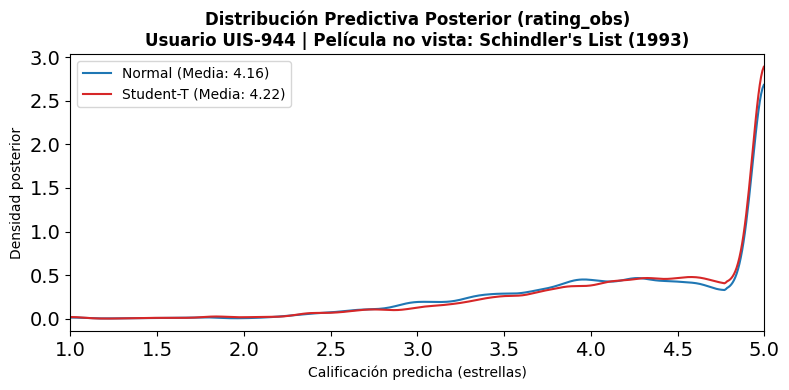

In [11]:
def comparar_usuario_detalle(id_usuario, top_n=8):
    u_idx = np.where(user_ids == id_usuario)[0][0]
    col_tit = 'movie_title' if 'movie_title' in items.columns else 'title'

    # 1. Historial real del usuario
    hist = ratings[ratings['user_id'] == id_usuario].merge(items[['movie_id', col_tit]], on='movie_id')
    print(f"=== PERFIL REAL ENCUESTADO ID {id_usuario} (Vistas: {len(hist)}) ===")
    display(hist[[col_tit, 'rating']].sort_values('rating', ascending=False))

    # 2. Candidatas no vistas
    vistas = ratings.loc[ratings['user_id'] == id_usuario, 'movie_idx'].unique()
    candidatos = np.setdiff1d(np.arange(len(movie_ids)), vistas)
    pares = pd.DataFrame({'user_idx': u_idx, 'movie_idx': candidatos, 'movie_id': movie_ids[candidatos]})

    _, y_norm = generar_rating_obs(traces['normal'], pares, 'normal')
    _, y_stud = generar_rating_obs(traces['student_t'], pares, 'student_t')

    pares['Normal_Pred'] = np.round(y_norm.mean(axis=0), 2)
    pares['Normal_HDI94'] = [f"[{np.percentile(y_norm[:, j], 3):.1f}, {np.percentile(y_norm[:, j], 97):.1f}]" for j in range(len(pares))]
    pares['StudentT_Pred'] = np.round(y_stud.mean(axis=0), 2)
    pares['StudentT_HDI94'] = [f"[{np.percentile(y_stud[:, j], 3):.1f}, {np.percentile(y_stud[:, j], 97):.1f}]" for j in range(len(pares))]

    top_df = pares.sort_values('StudentT_Pred', ascending=False).head(top_n).merge(items[['movie_id', col_tit]], on='movie_id')
    print(f"\n=== TOP {top_n} PELÍCULAS NO VISTAS: NORMAL vs. STUDENT-T ===")
    display(top_df[[col_tit, 'Normal_Pred', 'Normal_HDI94', 'StudentT_Pred', 'StudentT_HDI94']])

    # 3. Graficar la distribución predictiva posterior (rating_obs) de la #1 recomendada
    idx_top1 = pares['StudentT_Pred'].idxmax()
    titulo_top1 = items.loc[items['movie_id'] == pares.loc[idx_top1, 'movie_id'], col_tit].values[0]

    fig, ax = plt.subplots(figsize=(8, 4))
    az.plot_dist(y_norm[:, idx_top1], color='#1f77b4', label=f"Normal (Media: {y_norm[:, idx_top1].mean():.2f})", ax=ax)
    az.plot_dist(y_stud[:, idx_top1], color='#d62728', label=f"Student-T (Media: {y_stud[:, idx_top1].mean():.2f})", ax=ax)
    ax.set_title(f"Distribución Predictiva Posterior (rating_obs)\nUsuario UIS-{id_usuario} | Película no vista: {titulo_top1}", fontweight='bold')
    ax.set_xlabel("Calificación predicha (estrellas)")
    ax.set_ylabel("Densidad posterior")
    ax.set_xlim(1, 5)
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUT / f'ppc_usuario_{id_usuario}.png', dpi=300)
    plt.show()

comparar_usuario_detalle(ids_encuesta[0], top_n=8)